[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/msfasha/307401-Big-Data/blob/main/20261/Module%202%20-%20Introduction%20to%20Hadoop/Practical/Beyond_Excel_10_Million_Rows.ipynb)

<div style="border-top:4px solid #A83296;background:#F5EDF4;border-radius:0 0 10px 10px;padding:34px 32px 32px;font-family:Arial,Helvetica,sans-serif;margin:12px 0 24px;">
<div style="color:#56616D;font-size:12px;font-weight:700;letter-spacing:1.7px;margin:0 0 20px;">BIG DATA · PRACTICAL LECTURE &amp; LAB</div>
<h1 style="margin:0 0 12px;border:0;color:#493347;font-size:36px;line-height:1.18;">Beyond Excel:<br>Big Data Analytics on One PC</h1>
<div style="font-size:19px;color:#655263;line-height:1.45;">A practical bridge from the Five V’s to Hadoop and Spark</div>
<div style="margin-top:22px;border-top:1px solid #DCD0DA;padding-top:15px;font-size:14px;color:#2F343B;">10 million synthetic transactions · Pandas · Parallel Processing · MapReduce · DuckDB · Polars · Dask</div>
</div>

**Audience:** Big Data students | **Format:** conceptual lecture + hands-on Jupyter lab | **Case:** an online retailer with **10 million transactions**.

> **Essential lesson:** A dataset can exceed Excel's worksheet limit—or even the computer's RAM—without automatically requiring a Hadoop or Spark cluster. For many *batch analytics* problems, streaming data in chunks, efficient SQL engines, and multicore execution are enough. The trade-offs include time, disk I/O, temporary storage, and algorithmic limitations. **Not every workload can be solved just by waiting longer.**

**Learning outcomes:** distinguish file size from RAM usage; distinguish chunking, parallelism, MapReduce, and distributed computing; execute the *same* analytical question using Pandas, DuckDB, Polars, and Dask; explain batch versus real-time requirements; justify when distributed infrastructure is needed.

**Business question throughout:** *What is total revenue by sales region?* Every implementation should give the same answer.

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 00 · GETTING STARTED</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">Setup, safety, and hardware expectations</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Set up the tools and understand practical limits</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> A laptop can do serious analytics, but RAM and disk capacity still matter.</div>
</div>

- Run cells in order. A fresh run will regenerate the synthetic data file in a folder named `local_bigdata_lab` alongside the notebook.
- **Full classroom scenario:** `N_ROWS = 10_000_000`. The CSV may occupy **hundreds of megabytes to roughly 1 GB**, depending on formatting; disk space also covers temporary files. The actual size is measured in a later cell.
- Recommended: Python 3.10+, several GB of free disk, and ideally 8 GB RAM. Students with limited hardware can set `N_ROWS = 1_100_000` or `200_000` before running; the concepts are identical.
- We generate data **batch by batch** rather than creating 10 million Python objects in RAM. The generator is deterministic.
- Library setup: required: `numpy`, `pandas`, `matplotlib`; optional: `duckdb`, `polars`, `dask[dataframe]`. Optional demos skip gracefully if the package is unavailable. Install in a separate Jupyter cell if needed: `%pip install duckdb polars "dask[dataframe]"` and **restart the kernel** if the notebook requests it.
- No external dataset, cloud account, Hadoop or Spark is required. Creation and analysis happen locally.

In [ ]:
from pathlib import Path
import os, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_ROWS = 10_000_000        # Full demonstration; choose 200_000 for a quick rehearsal
WRITE_BATCH = 250_000     # Records generated per batch
READ_CHUNK = 200_000      # Pandas records processed per chunk
SEED = 2026
DATA_DIR = Path.cwd() / "local_bigdata_lab"
DATA_DIR.mkdir(exist_ok=True)
CSV_PATH = DATA_DIR / f"sales_{N_ROWS:,}.csv"  # Distinct filenames protect other runs
REGIONS = np.array(["North", "South", "East", "West"])
print("Output folder:", DATA_DIR)
print("Rows planned:", f"{N_ROWS:,}")

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 01 · THE BIG DATA QUESTION</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">From the Five V&#x27;s to an actual computing decision</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">From the Five V’s to choosing an appropriate technology</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> Start with the business workload, not the name of a technology.</div>
</div>

After studying **Volume, Velocity, Variety, Veracity, and Value**, consider what each means operationally. A big file is primarily a *volume* challenge; a stream demanding sub-second answers is also a *velocity* challenge. Distributed computing is a possible response—not the definition of Big Data.

Excel worksheets hold at most **1,048,576 rows**. This is a worksheet display limit, **not** a universal limit on Excel Power Query or the Data Model; those features may handle larger datasets depending on memory, configuration, and workload.

**Question:** Can we answer a sales-aggregation question without opening all rows in a spreadsheet? Yes: we need the *aggregate*, not 10 million visible spreadsheet rows.

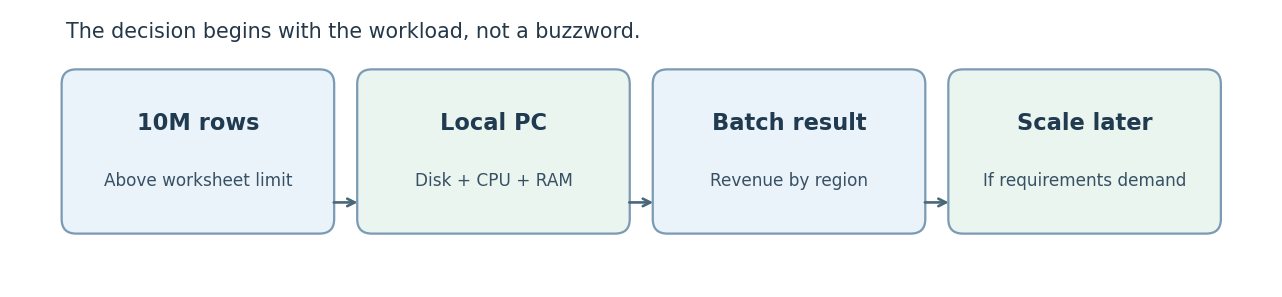

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 02 · BUILD OUR BUSINESS DATASET</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">Generate 10 million transactions without loading them all into RAM</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Generate ten million transactions incrementally</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> Writing data in batches avoids holding the entire dataset in RAM.</div>
</div>

**Synthetic data model:** `transaction_id`, `region`, `product`, `units`, `unit_price`, `revenue`. Values are invented and have no business significance. We store all revenue values as **integer cents** to avoid floating-point rounding surprises.

**Why stream generation?** Each iteration creates only `WRITE_BATCH` rows, writes them to disk, and releases that batch. We intentionally avoid `pd.concat()` on all batches.

In [ ]:
def generate_sales_csv(path, n_rows, batch_size=250_000, seed=2026):
    rng = np.random.default_rng(seed)
    products = np.array(["Laptop", "Phone", "Tablet", "Accessory"])
    prices = np.array([89900, 49900, 29900, 2500], dtype=np.int32) # cents
    start = time.perf_counter()
    with path.open("w", encoding="utf-8", newline="") as f:
        for offset in range(0, n_rows, batch_size):
            size = min(batch_size, n_rows - offset)
            product_id = rng.integers(0, len(products), size=size)
            units = rng.integers(1, 6, size=size, dtype=np.int16)
            batch = pd.DataFrame({
                "transaction_id": np.arange(offset + 1, offset + size + 1),
                "region": REGIONS[rng.integers(0, len(REGIONS), size=size)],
                "product": products[product_id],
                "units": units,
                "unit_price_cents": prices[product_id],
                "revenue_cents": (units.astype(np.int64) * prices[product_id]),
            })
            batch.to_csv(f, index=False, header=(offset == 0))
        # Write is completed here before size measurement.
    return time.perf_counter() - start

if not CSV_PATH.exists():
    generation_seconds = generate_sales_csv(CSV_PATH, N_ROWS, WRITE_BATCH, SEED)
    print(f"Generated {N_ROWS:,} rows in {generation_seconds:.1f} seconds")
else:
    print("Existing data file found. To regenerate, remove or rename it first:", CSV_PATH)
print(f"File size: {CSV_PATH.stat().st_size / 1024**2:,.1f} MiB")
print(pd.read_csv(CSV_PATH, nrows=5).to_string(index=False))

**Interpretation:** The CSV exists on disk; the notebook did not need to hold all 10 million rows as one DataFrame. A 10 GB dataset is not automatically impossible on a computer with less than 10 GB free RAM. However, disk space, working memory, intermediate results, and execution time still constrain what we can do.

**Reflection:** Why is processing 10 million rows into four regional totals different from sorting all 10 million rows in memory?

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 03 · THE BASELINE APPROACH</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">Pandas approach A: ordinary in-memory processing (optional)</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Read the entire dataset using Pandas</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> In-memory processing is convenient when the dataset comfortably fits.</div>
</div>

Pandas is excellent when data **comfortably fits in available RAM**. The CSV file size and DataFrame memory footprint are different: string columns and parsing can expand memory use substantially. For the 10-million-row file, we deliberately **skip** the full-load example by default to protect student computers.

In [ ]:
RUN_FULL_PANDAS = False  # Opt in only if your computer has sufficient RAM
if RUN_FULL_PANDAS:
    t0 = time.perf_counter()
    full = pd.read_csv(CSV_PATH)
    pandas_result = full.groupby("region")["revenue_cents"].sum().sort_index()
    print(f"Elapsed: {time.perf_counter()-t0:.2f} s")
    print(f"DataFrame memory: {full.memory_usage(deep=True).sum()/1024**2:.1f} MiB")
    del full
    gc.collect()
else:
    print("Skipped: no need to load all rows to answer our question.")

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 04 · WORKING WITH LIMITED MEMORY</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">Pandas approach B: sequential chunking (streaming batches)</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Process the file sequentially in chunks</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> Chunking controls peak memory; it does not automatically provide parallelism.</div>
</div>

A **chunk** is a manageable group of rows. We read a chunk, compute a subtotal for each region, and add those subtotals to a running total. This is memory-efficient because we keep only one chunk plus a tiny summary in memory. This is **sequential**, not parallel, and is a form of *out-of-core processing*.

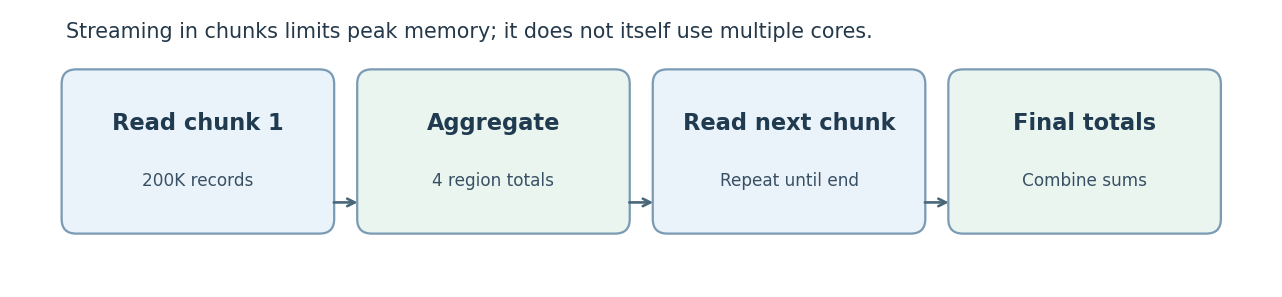

In [ ]:
def pandas_chunked_revenue(path, chunk_size=200_000):
    totals = pd.Series(dtype="int64")
    for chunk in pd.read_csv(path, chunksize=chunk_size,
                             usecols=["region", "revenue_cents"],
                             dtype={"region": "category", "revenue_cents": "int64"}):
        subtotal = chunk.groupby("region", observed=True)["revenue_cents"].sum()
        totals = totals.add(subtotal, fill_value=0)
    return totals.fillna(0).astype("int64").sort_index()

t0 = time.perf_counter()
reference = pandas_chunked_revenue(CSV_PATH, READ_CHUNK)
benchmarks = {"Pandas chunks": time.perf_counter() - t0}
print("Revenue by region ($):")
print((reference / 100).map(lambda v: f"${v:,.2f}"))
print(f"Total revenue: ${reference.sum()/100:,.2f}")
print(f"Chunked processing: {benchmarks['Pandas chunks']:.2f} s")

**The price of limited RAM:** streaming may require multiple disk scans, and some analytical operations (e.g., global sorting or high-cardinality joins) need temporary files or additional strategies. Chunking is not a universal solution, but it is effective for *combinable aggregates* such as sums, counts, and minima.

**Mini-lab:** Change `READ_CHUNK` to `50_000` and `500_000`. Which size performs best on your computer? Why is the largest chunk not guaranteed to be fastest?

<div style="margin:28px 0 14px;border-bottom:2px solid #E3DAE1;padding:0 0 9px;font-family:Arial,Helvetica,sans-serif;"><span style="color:#A83296;font-size:13px;font-weight:700;">FOCUS 4.1</span><h3 style="color:#2F343B;font-size:22px;line-height:1.3;margin:4px 0 0;">How does the `for` loop move between chunks?</h3></div>

`pd.read_csv(..., chunksize=...)` returns a **reader/iterator**, *not* a DataFrame containing all the rows. On each iteration, Pandas reads the **next** group of records automatically. There is no `skip`, `next file`, or manual offset to maintain.

**Watch what happens below:** We inspect only three small chunks (5 records each) to make the reading process visible. This example is intentionally tiny; the complete revenue calculation above processes **every** chunk until the file ends.

```text
CSV on disk → [rows 1–5] → [rows 6–10] → [rows 11–15] → ... → end of file
              loop 1        loop 2          loop 3
```

The loop does **not** keep earlier chunks unless you save them. Keeping all chunks in a list would defeat the memory-saving objective. Usually we retain only compact summaries or write matching rows directly to disk.

**Important:** this reader advances *sequentially*. It does not automatically create parallel workers.

In [ ]:
from itertools import islice

reader = pd.read_csv(CSV_PATH, chunksize=5, usecols=["transaction_id", "region", "revenue_cents"])
for number, chunk in enumerate(islice(reader, 3), start=1):
    print(f"Chunk {number}: transaction IDs {chunk.transaction_id.iloc[0]} to {chunk.transaction_id.iloc[-1]}")
reader.close()  # We stopped early; release the file handle.

# To process EVERY record, simply omit islice():
# for chunk in pd.read_csv(CSV_PATH, chunksize=READ_CHUNK):
#     ...  # process chunk; the iterator stops automatically at end-of-file

<div style="margin:28px 0 14px;border-bottom:2px solid #E3DAE1;padding:0 0 9px;font-family:Arial,Helvetica,sans-serif;"><span style="color:#A83296;font-size:13px;font-weight:700;">FOCUS 4.2</span><h3 style="color:#2F343B;font-size:22px;line-height:1.3;margin:4px 0 0;">Which operations are easy—or hard—with chunks?</h3></div>

Chunking is most helpful when we can **combine partial answers** into a correct final answer. It is not automatically suitable for every algorithm.

| Business question | Plain chunking? | Reason |
|---|---|---|
| What is total revenue? | **Easy** | Add each chunk's subtotal |
| What is average order value? | **Easy** | Keep total revenue **and count**; divide at the end |
| Which region has maximum revenue? | **Easy** | Keep per-region subtotals, then select the maximum |
| Which transactions belong to the North region? | **Easy if streamed** | Write matches into an output file; don't accumulate all matches in RAM |
| What is the exact median transaction value? | **Harder** | A median of chunk medians is generally **wrong**; needs a suitable selection or external-memory method |
| Sort **all 10 million** transactions by revenue | **Harder** | Sorting each chunk does **not** sort the entire dataset |
| Join two large transaction-level datasets | **Depends** | Some joins create large intermediate results; may require partitioning or disk spill |

**Worked conceptual example — sorting:** Imagine the first chunk contains `[8, 2, 12]`, and the second `[10, 1, 5]`. Sorting independently gives `[2, 8, 12]` and `[1, 5, 10]`. Concatenating those two sorted outputs is **not** globally sorted. A correct external merge sort sorts partitions, then **merges them in order**, often using disk files.

We do not need to write an external sorting algorithm ourselves. Analytical engines such as **DuckDB** and **Polars** offer optimized query plans; certain operations can use disk when memory is insufficient. This does **not** guarantee every workload succeeds on a small computer: execution may require substantial temporary disk space, and implementation/engine settings matter.

In [ ]:
# Small, executable proof that "sort each chunk and concatenate" is NOT a global sort.
chunk_a = [8, 2, 12]
chunk_b = [10, 1, 5]
individually_sorted = sorted(chunk_a) + sorted(chunk_b)
globally_sorted = sorted(chunk_a + chunk_b)
print("Sorted separately then concatenated:", individually_sorted)
print("Correct global order:             ", globally_sorted)
assert individually_sorted != globally_sorted

# A streaming aggregation, by comparison, combines correct partial answers.
print("Sum of partial sums:", sum(chunk_a) + sum(chunk_b))
print("Sum of all values: ", sum(chunk_a + chunk_b))

<div style="margin:28px 0 14px;border-bottom:2px solid #E3DAE1;padding:0 0 9px;font-family:Arial,Helvetica,sans-serif;"><span style="color:#A83296;font-size:13px;font-weight:700;">FOCUS 4.3</span><h3 style="color:#2F343B;font-size:22px;line-height:1.3;margin:4px 0 0;">Reduce input first; know when to switch tools</h3></div>

Even before chunking, reading **only required columns** (`usecols`) and choosing safe data types can reduce memory substantially. Do not automatically narrow numeric types if doing so risks overflow or loss of precision. The full demonstration above reads just `region` and `revenue_cents` and uses 64-bit integers for financial totals.

For repeated analyses, **Parquet** can be a better storage format than CSV: it is columnar, generally compressed, and supports reading selected columns efficiently. Conversion itself takes time and disk space, so it is a *choice*, not a requirement.

**Teaching question:** If a company needs (A) monthly revenue totals and (B) every transaction globally ordered by revenue, which task is naturally suited to simple chunking, and which needs additional algorithmic support?

**Optional demonstration (once DuckDB is installed in Section 7):**

```python
# Top 5 transactions, rather than sorting and returning 10 million rows:
# duckdb.sql(f"""SELECT transaction_id, revenue_cents
#                 FROM read_csv_auto('{CSV_PATH.as_posix()}')
#                 ORDER BY revenue_cents DESC LIMIT 5""").df()
```

A `TOP K` request can be easier than materializing a **complete global sort**. DuckDB decides the query strategy; it is not equivalent to a naïve `sort each Pandas chunk + concat` approach.

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 05 · USING MULTIPLE CPU CORES</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">Parallel processing on one PC: not the same as MapReduce</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Parallel processing on a single PC</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> Multiple workers can accelerate suitable tasks, but coordination adds overhead.</div>
</div>

A modern desktop has multiple CPU cores. **Parallel computing** means executing independent work at the same time; **chunking** simply splits work into smaller pieces. Python's `multiprocessing` uses separate processes, while **multithreading** shares a process and is widely used by native analytical engines.

A key design caveat: moving large DataFrames between Python processes can cost more time and memory than the computation itself. For a safe teaching exercise, workers each count integers from an inexpensive in-memory range. This illustrates parallelism clearly; it is **not** a claim that multiprocessing is better for our CSV aggregation.

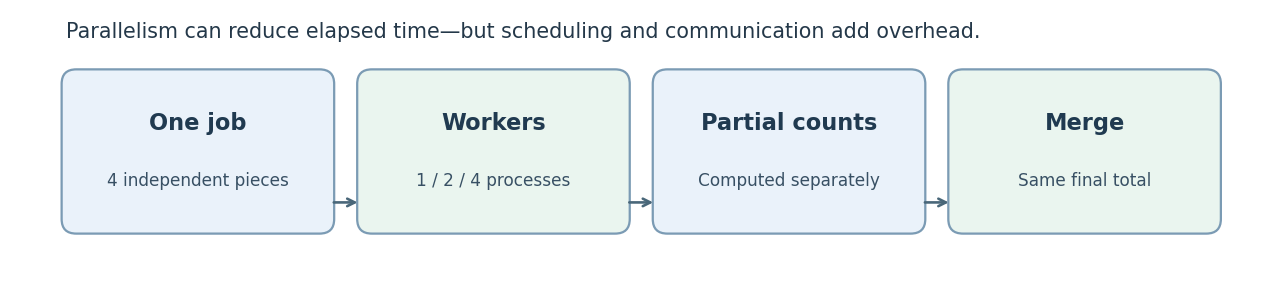

In [ ]:
# Small, portable example for Jupyter: threads coordinate independent chunks.
# We intentionally do not claim that Python threads speed up pure Python CPU loops.
from concurrent.futures import ThreadPoolExecutor

def count_matching_numbers(start, stop, divisor=7):
    return sum(x % divisor == 0 for x in range(start, stop))

RANGE_END = 200_000
parts = [(i, min(i + 50_000, RANGE_END)) for i in range(0, RANGE_END, 50_000)]

t0 = time.perf_counter()
sequential_count = sum(count_matching_numbers(a, b) for a, b in parts)
sequential_time = time.perf_counter() - t0

t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=4) as pool:
    partials = list(pool.map(lambda ab: count_matching_numbers(*ab), parts))
threaded_count = sum(partials)
threaded_time = time.perf_counter() - t0
assert sequential_count == threaded_count
print(f"Sequential: {sequential_time:.4f}s | Threaded: {threaded_time:.4f}s")
print("Identical count:", sequential_count)
print("Note: CPU-bound Python threads usually do NOT achieve true multicore speedups under the standard GIL.")

### Genuine multicore demonstration (separate `.py` script)

For CPU-intensive **pure Python** code, ordinary threads are usually restricted by CPython's Global Interpreter Lock (GIL). Separate processes can exploit different CPU cores. In Jupyter, multiprocessing pools often fail because the notebook's function objects cannot be imported by spawned worker processes, especially on Windows. To make the lesson robust, the next cell writes a small **standalone Python script**, which you execute using your terminal or the notebook's `!` command. It uses a proper `if __name__ == "__main__"` guard.

**Teaching focus:** measure time, verify results, and observe that more workers can be slower for small jobs.

In [ ]:
script = r"""import time
from concurrent.futures import ProcessPoolExecutor

def count_divisible(bounds):
    a, b = bounds
    return sum(x % 7 == 0 for x in range(a, b))

def main():
    limit = 1_000_000
    work = [(i, min(i+125_000, limit)) for i in range(0, limit, 125_000)]
    start = time.perf_counter()
    seq = sum(map(count_divisible, work))
    t_seq = time.perf_counter()-start
    start = time.perf_counter()
    with ProcessPoolExecutor(max_workers=2) as pool:
        par = sum(pool.map(count_divisible, work))
    t_par = time.perf_counter()-start
    assert seq == par
    print(f"Equal results: {seq:,}")
    print(f"Sequential: {t_seq:.3f}s; 2 processes: {t_par:.3f}s")
    print("Speedup:", round(t_seq/t_par, 2), "x")

if __name__ == "__main__":
    main()
"""
MULTIPROCESS_SCRIPT = DATA_DIR / "local_multiprocessing_demo.py"
MULTIPROCESS_SCRIPT.write_text(script, encoding="utf-8")
print("Created:", MULTIPROCESS_SCRIPT)
print("Run in a terminal: python", MULTIPROCESS_SCRIPT)

In [ ]:
# Run the genuine multicore demonstration without leaving Jupyter.
# This launches a separate Python process, so it also works on Windows.
import subprocess, sys
process = subprocess.run([sys.executable, str(MULTIPROCESS_SCRIPT)],
                         capture_output=True, text=True, check=True)
print(process.stdout)

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 06 · THE MAPREDUCE CONCEPT</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">MapReduce: a pattern, not a prerequisite for parallelism</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Map partial results, then reduce them</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> MapReduce is a useful pattern, not a requirement for parallel computing.</div>
</div>

**Map:** compute a partial result for each partition (e.g., revenue totals per region). **Reduce:** combine partial results into one final answer. We have already used this principle in our chunked Pandas example—even though the chunks ran sequentially! *MapReduce-style* work can be sequential, local parallel, or distributed. **Hadoop MapReduce** is a specific distributed framework with scheduling, storage, and fault tolerance; it is not required here.

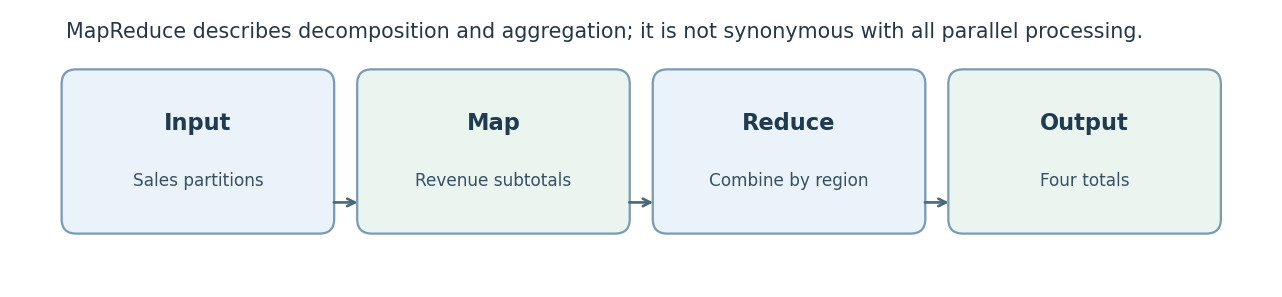

In [ ]:
# A tiny readable Map-then-Reduce example; uses no cluster or special framework.
small_sales = [
    ("North", 100), ("South", 250), ("North", 50), ("West", 80)
]
from collections import defaultdict
region_totals = defaultdict(int)
for region, revenue_cents in small_sales:   # Map emits (region, revenue)
    region_totals[region] += revenue_cents  # Reduce combines by key
print(dict(region_totals))

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 07 · LOCAL SQL ANALYTICS</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">DuckDB: SQL directly over a large CSV</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">DuckDB processes CSV data with SQL</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> A lightweight analytical engine can optimize and parallelize queries locally.</div>
</div>

DuckDB is an **in-process analytical database engine**. It can stream CSV scans, plan queries, and use multiple CPU cores without requiring a database server or distributed cluster. It can also spill some intermediate operations to disk. We query the file *directly*—no separate import step.

In [ ]:
try:
    import duckdb
except ImportError:
    print('DuckDB not installed. Install: %pip install duckdb')
else:
    t0=time.perf_counter()
    duck_result = duckdb.connect().execute("""
        SELECT region, SUM(revenue_cents)::BIGINT AS revenue_cents
        FROM read_csv_auto(?, header=true)
        GROUP BY region ORDER BY region
    """, parameters=[str(CSV_PATH)]).df().set_index("region")["revenue_cents"]
    benchmarks["DuckDB"] = time.perf_counter()-t0
    pd.testing.assert_series_equal(duck_result.sort_index(), reference, check_names=False)
    print(duck_result)
    print(f"DuckDB: {benchmarks['DuckDB']:.2f}s — matches Pandas")

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 08 · MODERN DATAFRAMES</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">Polars: lazy and multithreaded DataFrame processing</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Polars uses lazy query execution</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> An optimized query plan can avoid unnecessary work and use CPU cores.</div>
</div>

Polars can build an optimized **lazy query plan**, push down a column projection, and run supported operations in parallel. `scan_csv()` creates a lazy scan; `.collect()` executes it. No custom MapReduce functions are required.

In [ ]:
try:
    import polars as pl
except ImportError:
    print('Polars not installed. Install: %pip install polars')
else:
    t0=time.perf_counter()
    polars_frame = (pl.scan_csv(str(CSV_PATH))
        .group_by("region")
        .agg(pl.col("revenue_cents").sum())
        .sort("region")
        .collect())
    polars_result = pd.Series(dict(zip(polars_frame["region"].to_list(), polars_frame["revenue_cents"].to_list())), dtype="int64").sort_index()
    benchmarks["Polars"] = time.perf_counter()-t0
    pd.testing.assert_series_equal(polars_result.sort_index(), reference, check_names=False)
    print(polars_frame)
    print(f"Polars: {benchmarks['Polars']:.2f}s — matches Pandas")

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 09 · PARTITIONED COMPUTATION</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">Dask: partitioned DataFrames and task scheduling on one PC</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Dask organizes work into tasks and partitions</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> Dask can execute on one PC or scale out when required.</div>
</div>

Dask divides operations into tasks on partitions. `read_csv()` constructs a collection; `.compute()` triggers execution. The **local threaded scheduler** can execute supported work concurrently on one machine, and a Dask cluster is optional—not required. Unlike Polars or DuckDB, Dask's abstraction resembles parallel Pandas partitions.

In [ ]:
try:
    import dask.dataframe as dd
except ImportError:
    print('Dask not installed. Install: %pip install "dask[dataframe]"')
else:
    t0=time.perf_counter()
    ddf = dd.read_csv(str(CSV_PATH), blocksize="32MB")
    dask_result = ddf.groupby("region")["revenue_cents"].sum().compute(scheduler="threads")
    dask_result = dask_result.sort_index().astype("int64")
    benchmarks["Dask"] = time.perf_counter()-t0
    pd.testing.assert_series_equal(dask_result, reference, check_names=False)
    print(dask_result)
    print(f"Dask: {benchmarks['Dask']:.2f}s — matches Pandas")

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 10 · MEASURE, DO NOT GUESS</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">Compare measured execution times—not hypothetical benchmarks</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Compare actual execution times</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> Benchmark results depend on the computer, dataset, and query.</div>
</div>

The timing chart below uses values measured on **your** computer for the current run. Results depend on disk speed, RAM, CPU cores, CSV parsing, task overhead, and operating-system file caching. These are **single-run classroom demonstrations**, not controlled performance benchmarks: repeat multiple times, vary execution order, and record medians before drawing conclusions.

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
labels = list(benchmarks)
seconds = [benchmarks[k] for k in labels]
ax.barh(labels, seconds)
ax.set_xlabel("Elapsed time (seconds; lower is better)")
ax.set_title("Measured local batch aggregation time — this computer")
ax.invert_yaxis()
for i, v in enumerate(seconds):
    ax.text(v, i, f" {v:.2f}s", va="center")
plt.tight_layout()
plt.show()
print("Reminder: identical output matters more than a single fastest run.")

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 11 · TECHNOLOGY DECISIONS</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">Choosing the right technique (a decision framework)</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Choose the simplest workable solution</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> Different workloads justify different tools and infrastructure.</div>
</div>

| Workload or constraint | Sensible first option | Why |
|---|---|---|
| Fits comfortably in RAM | Pandas | Familiar and flexible |
| Larger than RAM; simple sums/counts | Pandas chunks | Simple, predictable memory use |
| Large CSV / Parquet + SQL analytics | DuckDB | SQL execution and query optimization |
| DataFrame pipelines, complex column operations | Polars | Lazy planning, efficient multithreading |
| Partitioned Python workflows, future cluster option | Dask | Task scheduler and parallel partitions |
| CPU-bound custom Python tasks | Multiprocessing | Multiple processes bypass standard CPython GIL |
| Data too large / demanding for a machine or needs distributed reliability | Spark, Hadoop ecosystem, distributed Dask, etc. | Scale out and coordinate computation |

**Key conceptual guardrails:**
1. **Chunking ≠ parallel processing.** Processing one chunk at a time may use only one core.
2. **Parallelism ≠ distributed computing.** Many CPU cores can exist inside one computer.
3. **MapReduce ≠ the only parallel processing model.** Vectorized pipelines, relational query plans, multithreading, and task graphs are alternatives.
4. **Volume ≠ velocity.** Completing a 10 GB report overnight is different from updating a dashboard in 100 milliseconds.
5. **Parallel speedup is not guaranteed.** Overhead, disk bottlenecks, and uneven tasks can dominate.
6. **10 GB is not a universal threshold.** Whether data is “big” depends on processing requirements and available resources.

### The transition to Hadoop and Spark

So far, one PC has produced business results from a 10-million-row dataset. When the demands become **larger than practical disk/compute capacity, too slow for service-level targets, multi-user, fault-tolerant at scale, or continuously streaming**, distributed engines may be justified. Hadoop is better described as an *ecosystem of distributed storage and processing components* (including HDFS, YARN, and MapReduce), not literally a conventional operating system. Spark provides a distributed execution engine with higher-level APIs and can also run locally.

<div style="margin:34px 0 22px 0;background:#F7F3F7;border-left:4px solid #C8ABC3;border-radius:0 10px 10px 0;padding:22px 27px 23px;font-family:Arial,Helvetica,sans-serif;line-height:1.55;">
<div style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;color:#56616D;font-weight:700;margin-bottom:9px;">SECTION 12 · DISCUSS AND PRACTICE</div>
<h2 style="border:0;margin:0 0 7px 0;padding:0;background:none;font-size:27px;line-height:1.2;color:#493347;font-weight:750;">Class discussion and exercises</h2>
<div style="font-size:16px;color:#655263;margin:0 0 15px 0;">Apply the concepts to realistic Big Data cases</div>
<div style="border-top:1px solid #DED2DC;padding-top:11px;font-size:14px;color:#2F343B;"><strong>Central idea:</strong> Students should explain both when a local PC works and when it does not.</div>
</div>

**Exercise A — Describe the bottleneck.** A file is 10 GB and the PC has 8 GB RAM. Explain when chunked batch aggregation is feasible; identify at least two situations in which the answer might instead require a different algorithm or infrastructure.

**Exercise B — Change the question.** Modify the chunked Pandas function to calculate revenue by **product**, not region. Use only the required CSV columns.

**Exercise C — Repeated timings.** Run Pandas chunks with `READ_CHUNK` of 50,000, 200,000, and 500,000 on a small dataset. Repeat each run three times. Explain performance variability.

**Exercise D — Reasoning about parallelism.** Execute `local_multiprocessing_demo.py`, record timings, and explain why the two-process version might be slower than sequential execution.

**Exercise E — Recommend a tool.** A retail company needs: (a) a nightly 10 GB regional sales report, (b) complex interactive analysis from Parquet, (c) sub-second fraud alerts from thousands of events/second, and (d) a 5 PB historical archive. Propose tools and explain the required workload characteristics before naming products.

**Exercise F — MapReduce.** Draw one Map/Reduce-style revenue-aggregation example. Explain why it does **not** require Hadoop, and identify one kind of parallel task that is not naturally represented by a single Map/Reduce operation.

### Instructor wrap-up

> **We should not jump from the Five V's straight to a cluster. First ask: What decision must be computed? How much data needs to be in memory at once? What latency is acceptable? Can we use disk streaming, partitioning, an optimized local engine, or multiple cores? Only then ask whether distributed infrastructure is justified.**

**Optional next lecture:** Hadoop (HDFS for storage, YARN for cluster resources, MapReduce as one computation model) and Spark (distributed execution), compared with these local tools.